In [5]:
!pip install selenium

   ---------------------------------------- 0.0/11.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.8 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.8 MB 2.0 MB/s eta 0:00:06
   --- ------------------------------------ 1.0/11.8 MB 2.3 MB/s eta 0:00:05
   ------ --------------------------------- 1.8/11.8 MB 2.7 MB/s eta 0:00:04
   -------- ------------------------------- 2.6/11.8 MB 3.1 MB/s eta 0:00:03
   ------------ --------------------------- 3.7/11.8 MB 3.5 MB/s eta 0:00:03
   ----------------- ---------------------- 5.2/11.8 MB 4.2 MB/s eta 0:00:02
   ------------------------ --------------- 7.1/11.8 MB 4.9 MB/s eta 0:00:01
   -------------------------------- ------- 9.4/11.8 MB 5.6 MB/s eta 0:00:01
   ---------------------------------------  11.5/11.8 MB 6.2 MB/s eta 0:00:01
   ---------------------------------------- 11.8/11.8 MB 6.0 MB/s  0:00:02

   ----- ---------------------------------- 1/7 [wsproto]
   ----------------- -----------

In [2]:
import pandas as pd

In [21]:
from selenium import webdriver
from bs4 import BeautifulSoup
import pandas as pd
import re
import time

driver = webdriver.Chrome()

model_urls = [
    'https://www.cardekho.com/maruti/swift',
    'https://www.cardekho.com/maruti/baleno',
    'https://www.cardekho.com/maruti/brezza',
    'https://www.cardekho.com/maruti/dzire',
    'https://www.cardekho.com/maruti/fronx',
    'https://www.cardekho.com/maruti/wagon-r',
    'https://www.cardekho.com/maruti/alto-k10',
    'https://www.cardekho.com/tata/punch',
    'https://www.cardekho.com/tata/tiago',
    'https://www.cardekho.com/tata/altroz',
    'https://www.cardekho.com/tata/punch-ev',
    'https://www.cardekho.com/tata/tiago-ev',
    'https://www.cardekho.com/hyundai/creta',
    'https://www.cardekho.com/hyundai/i20',
    'https://www.cardekho.com/hyundai/verna',
    'https://www.cardekho.com/hyundai/exter',
    'https://www.cardekho.com/hyundai/grand-i10-nios',
    'https://www.cardekho.com/kia/seltos',
    'https://www.cardekho.com/kia/carens',
    'https://www.cardekho.com/mahindra/thar',
    'https://www.cardekho.com/mahindra/scorpio-n',
    'https://www.cardekho.com/mahindra/xev-9e',
    'https://www.cardekho.com/toyota/innova-hycross',
    'https://www.cardekho.com/toyota/innova-crysta',
    'https://www.cardekho.com/honda/elevate',
    'https://www.cardekho.com/skoda/slavia',
    'https://www.cardekho.com/volkswagen/virtus',
    'https://www.cardekho.com/renault/triber',
    'https://www.cardekho.com/mg/hector',
    'https://www.cardekho.com/mg/windsor-ev',
    'https://www.cardekho.com/maruti/grand-vitara',
    'https://www.cardekho.com/maruti/ertiga',
    'https://www.cardekho.com/maruti/xl6',
    'https://www.cardekho.com/maruti/celerio',
    'https://www.cardekho.com/maruti/s-presso',
    'https://www.cardekho.com/maruti/ignis',
    'https://www.cardekho.com/maruti/eeco',
    'https://www.cardekho.com/maruti/jimny',
    'https://www.cardekho.com/maruti/invicto',
    'https://www.cardekho.com/tata/nexon',
    'https://www.cardekho.com/tata/harrier',
    'https://www.cardekho.com/tata/safari',
    'https://www.cardekho.com/tata/tigor',
    'https://www.cardekho.com/tata/nexon-ev',
    'https://www.cardekho.com/tata/curvv',
    'https://www.cardekho.com/tata/curvv-ev',
    'https://www.cardekho.com/tata/tigor-ev',
    'https://www.cardekho.com/hyundai/venue',
    'https://www.cardekho.com/hyundai/alcazar',
    'https://www.cardekho.com/hyundai/tucson',
    'https://www.cardekho.com/hyundai/aura',
    'https://www.cardekho.com/hyundai/i20-n-line',
    'https://www.cardekho.com/hyundai/venue-n-line',
    'https://www.cardekho.com/mahindra/xuv700',
    'https://www.cardekho.com/mahindra/xuv-3xo',
    'https://www.cardekho.com/mahindra/thar-roxx',
    'https://www.cardekho.com/mahindra/bolero',
    'https://www.cardekho.com/mahindra/bolero-neo',
    'https://www.cardekho.com/mahindra/xuv400-ev',
    'https://www.cardekho.com/mahindra/marazzo',
    'https://www.cardekho.com/kia/sonet',
    'https://www.cardekho.com/kia/ev6',
    'https://www.cardekho.com/toyota/fortuner',
    'https://www.cardekho.com/toyota/urban-cruiser-hyryder',
    'https://www.cardekho.com/toyota/glanza',
    'https://www.cardekho.com/toyota/fortuner-legender',
    'https://www.cardekho.com/toyota/rumion',
    'https://www.cardekho.com/toyota/taisor',
    'https://www.cardekho.com/toyota/camry',
    'https://www.cardekho.com/toyota/hilux',
    'https://www.cardekho.com/honda/city',
    'https://www.cardekho.com/honda/amaze',
    'https://www.cardekho.com/honda/city-hybrid',
    'https://www.cardekho.com/skoda/kushaq',
    'https://www.cardekho.com/skoda/kodiaq',
    'https://www.cardekho.com/skoda/superb',
    'https://www.cardekho.com/volkswagen/taigun',
    'https://www.cardekho.com/volkswagen/tiguan',
    'https://www.cardekho.com/renault/kiger',
    'https://www.cardekho.com/renault/kwid',
    'https://www.cardekho.com/nissan/magnite',
    'https://www.cardekho.com/nissan/x-trail',
    'https://www.cardekho.com/mg/astor',
    'https://www.cardekho.com/mg/zs-ev',
    'https://www.cardekho.com/mg/comet-ev',
    'https://www.cardekho.com/mg/gloster',
    'https://www.cardekho.com/jeep/compass',
    'https://www.cardekho.com/jeep/meridian',
    'https://www.cardekho.com/jeep/wrangler',
    'https://www.cardekho.com/citroen/c3',
    'https://www.cardekho.com/citroen/basalt',
    'https://www.cardekho.com/citroen/c3-aircross',
    'https://www.cardekho.com/citroen/ec3'
]

brand = []
model = []
variant = []
price = []
fuel = []
transmission = []
mileage = []
mileage_unit = []
power = []

pattern = (r'₹\s*([\d.]+)\s*Lakh\s*\*?\s*Get On-Road Price\s*'
           r'(Petrol|Diesel|CNG|Electric)\s*(Manual|Automatic)\s*'
           r'(?:([\d.]+)\s*(kmpl|km/kg))?\s*'
           r'(?:([\d.]+)\s*bhp)?')

for url in model_urls:
    print(url)

    driver.get(url)
    time.sleep(3)
    driver.execute_script('window.scrollTo(0, document.body.scrollHeight / 2)')
    time.sleep(2)
    soup = BeautifulSoup(driver.page_source, 'html.parser')

    
    car_name = soup.find('h1').text.strip()

    
    text = ' '.join(soup.stripped_strings)
    cards = list(re.finditer(pattern, text))

    for m in cards:
        
        before = text[max(0, m.start() - 80):m.start()]
        name = re.split(r'View Offers|Best Pick For You', before)[-1].strip()

        brand.append(car_name.split()[0])
        model.append(car_name)
        variant.append(name)
        price.append(m.group(1))
        fuel.append(m.group(2))
        transmission.append(m.group(3))
        mileage.append(m.group(4))
        mileage_unit.append(m.group(5))
        power.append(m.group(6))

    if len(cards) == 0:
        i = text.find('Get On-Road Price')
        print('DEBUG:', text[max(0, i - 100):i + 200] if i != -1 else 'phrase not found, page length ' + str(len(text)))

    print(len(cards), 'variants found')


driver.quit()

df = pd.DataFrame({
    'Brand': brand,
    'Model': model,
    'Variant': variant,
    'Price_Lakh': price,
    'Fuel_Type': fuel,
    'Transmission': transmission,
    'Mileage': mileage,
    'Mileage_Unit': mileage_unit,
    'Power_bhp': power
})

df.to_csv('car_data.csv', index=False)
df

https://www.cardekho.com/maruti/swift
17 variants found
https://www.cardekho.com/maruti/baleno
DEBUG:  Photos Shorts 7 Colors Maruti Suzuki Baleno 4.7 14 Reviews Rate & Win ₹1000 Rs. 5.99 - 9.99 Lakh * Get On-Road Price *Ex-Showroom Price in New Delhi Compare with Old Maruti Baleno 2022-2026 Get Diwali Offers Get Diwali Offers Hurry up to lock festive offers! Maruti Suzuki Baleno Quick Insights 1 / 
0 variants found
https://www.cardekho.com/maruti/brezza
DEBUG: tos 9 Colors 360º View Maruti Suzuki Brezza 4.5 41 Reviews Rate & Win ₹1000 Rs. 7.50 - 13.71 Lakh * Get On-Road Price *Ex-Showroom Price in New Delhi Get Diwali Offers Get Diwali Offers Hurry up to lock festive offers! Quick Insights 1 / 7 Summary A dependable family SUV that seats five, offers a co
0 variants found
https://www.cardekho.com/maruti/dzire
DEBUG: - 382 Litres Safety Rating - 5 Star (Global NCAP), 5 Star (Bharat NCAP) more Rs. 6.31 - 9.54 Lakh * Get On-Road Price *Ex-Showroom Price in New Delhi Get Diwali Offers Get

,Brand,Model,Variant,Price_Lakh,Fuel_Type,Transmission,Mileage,Mileage_Unit,Power_bhp
0,Maruti,Maruti Suzuki Swift,Swift ZXi Plus AMT,8.74,Petrol,Automatic,26.25,kmpl,81.80
1,Maruti,Maruti Suzuki Swift,Swift LXi,5.84,Petrol,Manual,25.35,kmpl,81.80
2,Maruti,Maruti Suzuki Swift,Swift VXi,6.68,Petrol,Manual,25.35,kmpl,81.80
3,Maruti,Maruti Suzuki Swift,Swift VXi Opt,6.94,Petrol,Manual,25.35,kmpl,81.80
4,Maruti,Maruti Suzuki Swift,Swift VXi AMT,7.13,Petrol,Automatic,26.25,kmpl,81.80
...,...,...,...,...,...,...,...,...,...
755,Citroen,Citroen Aircross X,Aircross Turbo Max,12.97,Petrol,Manual,18.5,kmpl,108.62
756,Citroen,Citroen Aircross X,Aircross X Turbo Max 7 Seater,13.35,Petrol,Manual,18.5,kmpl,108.62
757,Citroen,Citroen Aircross X,Aircross X Turbo Max 7 Seater DT,13.55,Petrol,Manual,18.5,kmpl,108.62
758,Citroen,Citroen Aircross X,Aircross Turbo Max AT,14.14,Petrol,Automatic,17.6,kmpl,108.62


In [22]:
df

,Brand,Model,Variant,Price_Lakh,Fuel_Type,Transmission,Mileage,Mileage_Unit,Power_bhp
0,Maruti,Maruti Suzuki Swift,Swift ZXi Plus AMT,8.74,Petrol,Automatic,26.25,kmpl,81.80
1,Maruti,Maruti Suzuki Swift,Swift LXi,5.84,Petrol,Manual,25.35,kmpl,81.80
2,Maruti,Maruti Suzuki Swift,Swift VXi,6.68,Petrol,Manual,25.35,kmpl,81.80
3,Maruti,Maruti Suzuki Swift,Swift VXi Opt,6.94,Petrol,Manual,25.35,kmpl,81.80
4,Maruti,Maruti Suzuki Swift,Swift VXi AMT,7.13,Petrol,Automatic,26.25,kmpl,81.80
...,...,...,...,...,...,...,...,...,...
755,Citroen,Citroen Aircross X,Aircross Turbo Max,12.97,Petrol,Manual,18.5,kmpl,108.62
756,Citroen,Citroen Aircross X,Aircross X Turbo Max 7 Seater,13.35,Petrol,Manual,18.5,kmpl,108.62
757,Citroen,Citroen Aircross X,Aircross X Turbo Max 7 Seater DT,13.55,Petrol,Manual,18.5,kmpl,108.62
758,Citroen,Citroen Aircross X,Aircross Turbo Max AT,14.14,Petrol,Automatic,17.6,kmpl,108.62


In [23]:
import numpy as np

df_clean = df.copy()

numeric_cols = ["Price_Lakh", "Mileage", "Power_bhp"]
for col in numeric_cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

df_clean["Variant"] = df_clean["Variant"].apply(
    lambda x: str(x).split("rpm")[0].split("View")[0].strip()
)

print(df_clean.info())
df_clean.describe()

<class 'pandas.DataFrame'>
RangeIndex: 760 entries, 0 to 759
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Brand         760 non-null    str    
 1   Model         760 non-null    str    
 2   Variant       760 non-null    str    
 3   Price_Lakh    760 non-null    float64
 4   Fuel_Type     760 non-null    str    
 5   Transmission  760 non-null    str    
 6   Mileage       485 non-null    float64
 7   Mileage_Unit  485 non-null    str    
 8   Power_bhp     758 non-null    float64
dtypes: float64(3), str(6)
memory usage: 53.6 KB
None


,Price_Lakh,Mileage,Power_bhp
count,760.000000,485.000000,758.000000
mean,16.435382,19.230165,123.969327
std,6.879292,4.404829,33.773004
min,4.530000,8.200000,55.920000
25%,11.190000,17.500000,101.640000
50%,15.655000,19.100000,114.000000
75%,20.000000,20.970000,165.965000
max,48.770000,35.340000,227.000000


In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
#plt.rcParams["figure.dpi"] = 120

bins = [0, 85, 115, 150, 250]
labels = ["Sub-85 bhp", "85-115 bhp", "115-150 bhp", "150+ bhp"]
df_clean["Power_Segment"] = pd.cut(df_clean["Power_bhp"], bins=bins, labels=labels)

df_clean["Mileage_Imputed"] = df_clean.groupby("Power_Segment")["Mileage"].transform(
    lambda x: x.fillna(x.median())
)
df_clean["Mileage_Imputed"] = df_clean["Mileage_Imputed"].fillna(df_clean["Mileage"].median()).round(2)

print("Data ready! Null check on Mileage_Imputed:", df_clean["Mileage_Imputed"].isnull().sum())

Data ready! Null check on Mileage_Imputed: 0


C:\Users\koush\AppData\Local\Temp\ipykernel_17528\2854748748.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(


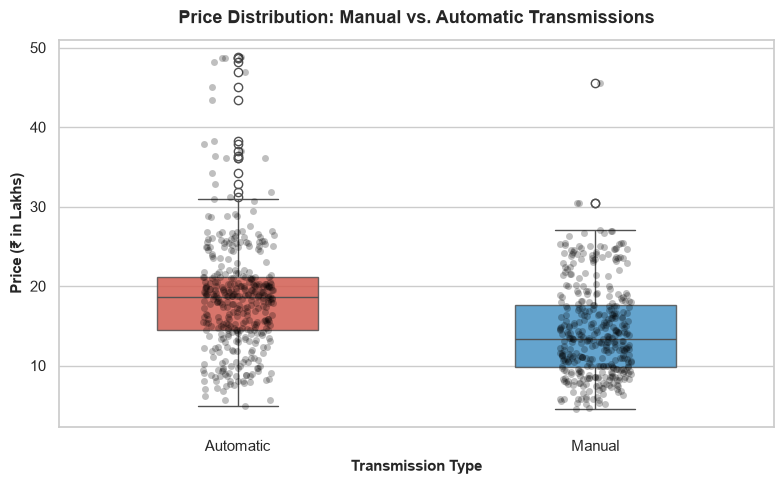

In [25]:
plt.figure(figsize=(8, 5))
palette = {"Manual": "#3498db", "Automatic": "#e74c3c"}

ax = sns.boxplot(
    data=df_clean,
    x="Transmission",
    y="Price_Lakh",
    palette=palette,
    width=0.45,
    boxprops=dict(alpha=0.85)
)

sns.stripplot(
    data=df_clean,
    x="Transmission",
    y="Price_Lakh",
    color="black",
    alpha=0.25,

)

plt.title("Price Distribution: Manual vs. Automatic Transmissions", fontsize=13, weight="bold", pad=12)
plt.xlabel("Transmission Type", fontsize=11, weight="semibold")
plt.ylabel("Price (₹ in Lakhs)", fontsize=11, weight="semibold")
plt.tight_layout()
plt.show()

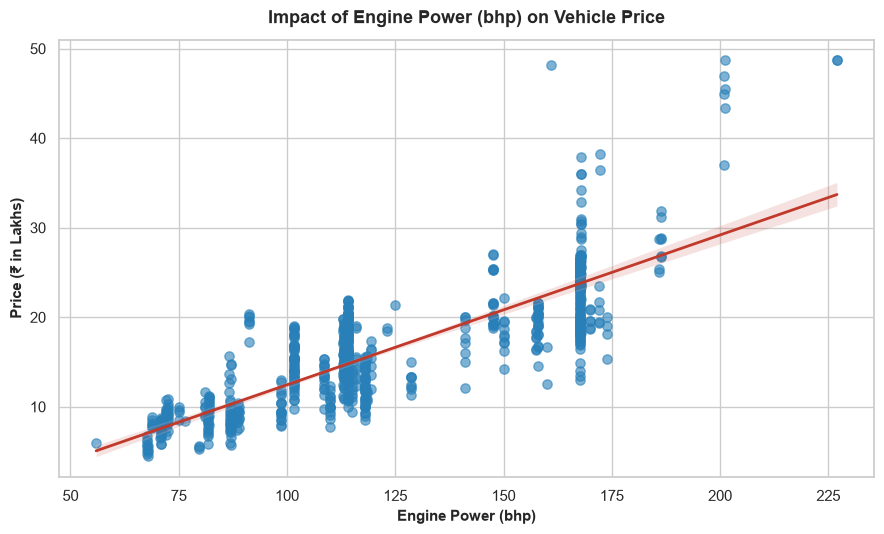

In [26]:
plt.figure(figsize=(9, 5.5))

sns.regplot(
    data=df_clean,
    x="Power_bhp",
    y="Price_Lakh",
    scatter_kws={"alpha": 0.6, "color": "#2980b9", "s": 45},
    line_kws={"color": "#c0392b", "linewidth": 2}
)

plt.title("Impact of Engine Power (bhp) on Vehicle Price", fontsize=13, weight="bold", pad=12)
plt.xlabel("Engine Power (bhp)", fontsize=11, weight="semibold")
plt.ylabel("Price (₹ in Lakhs)", fontsize=11, weight="semibold")
plt.tight_layout()
plt.show()

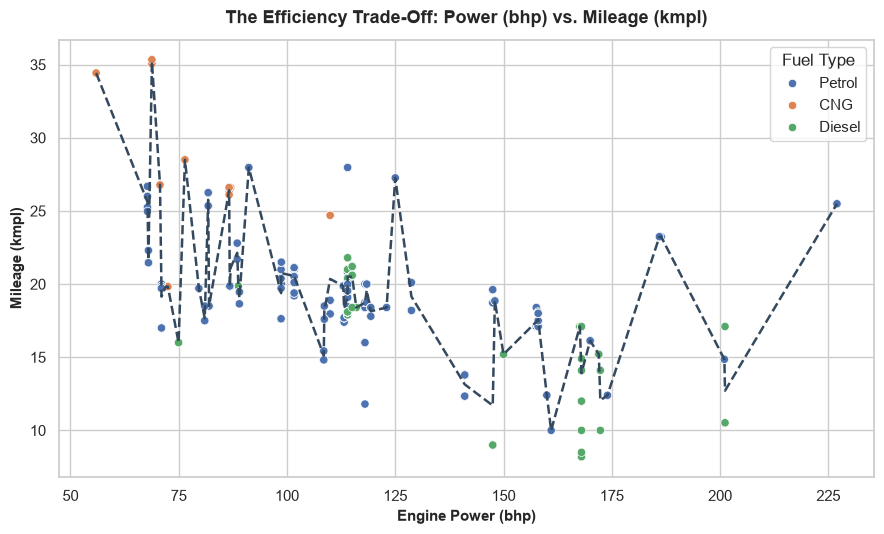

In [27]:
plt.figure(figsize=(9, 5.5))

sns.scatterplot(
    data=df_clean,
    x="Power_bhp",
    y="Mileage_Imputed",
    hue="Fuel_Type",
)

sns.lineplot(
    data=df_clean,
    x="Power_bhp",
    y="Mileage_Imputed",
    color="#34495e",
    errorbar=None,
    linewidth=1.8,
    linestyle="--"
)

plt.title("The Efficiency Trade-Off: Power (bhp) vs. Mileage (kmpl)", fontsize=13, weight="bold", pad=12)
plt.xlabel("Engine Power (bhp)", fontsize=11, weight="semibold")
plt.ylabel("Mileage (kmpl)", fontsize=11, weight="semibold")
plt.legend(title="Fuel Type", frameon=True)
plt.tight_layout()
plt.show()

C:\Users\koush\AppData\Local\Temp\ipykernel_17528\965894175.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


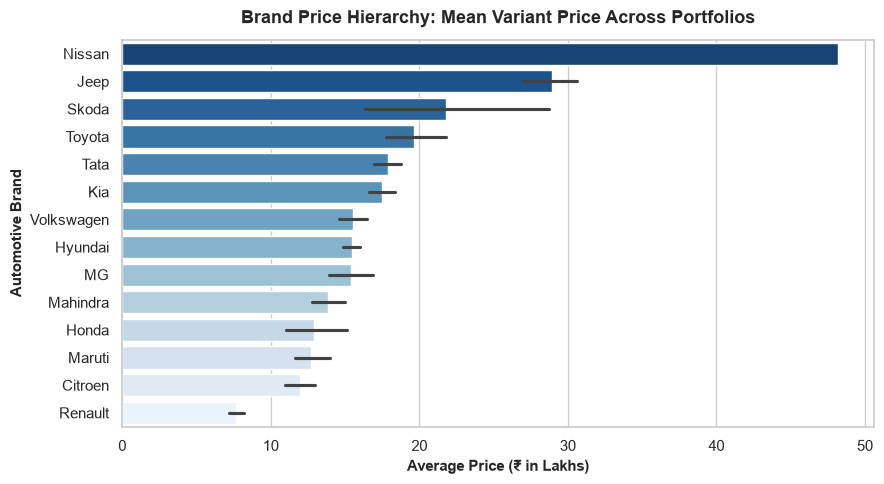

In [28]:
plt.figure(figsize=(9, 5))

brand_order = (
    df_clean.groupby("Brand")["Price_Lakh"]
    .mean()
    .sort_values(ascending=False)
    .index
)

ax = sns.barplot(
    data=df_clean,
    y="Brand",
    x="Price_Lakh",
    order=brand_order,
    palette="Blues_r",
)

plt.title("Brand Price Hierarchy: Mean Variant Price Across Portfolios", fontsize=13, weight="bold", pad=12)
plt.xlabel("Average Price (₹ in Lakhs)", fontsize=11, weight="semibold")
plt.ylabel("Automotive Brand", fontsize=11, weight="semibold")
plt.tight_layout()
plt.show()

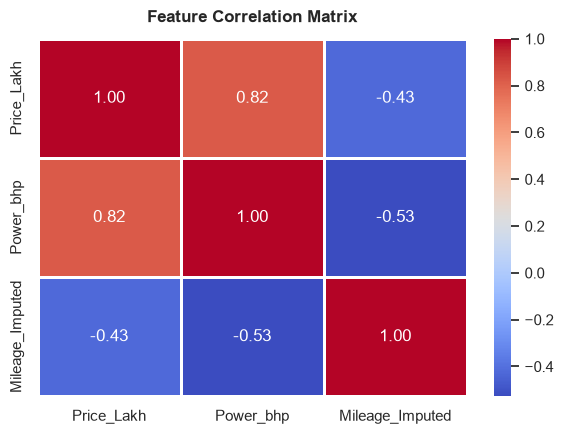

In [29]:
plt.figure(figsize=(6, 4.5))

corr_matrix = df_clean[["Price_Lakh", "Power_bhp", "Mileage_Imputed"]].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=1,
    cbar=True
)

plt.title("Feature Correlation Matrix", fontsize=12, weight="bold", pad=12)
plt.tight_layout()
plt.show()

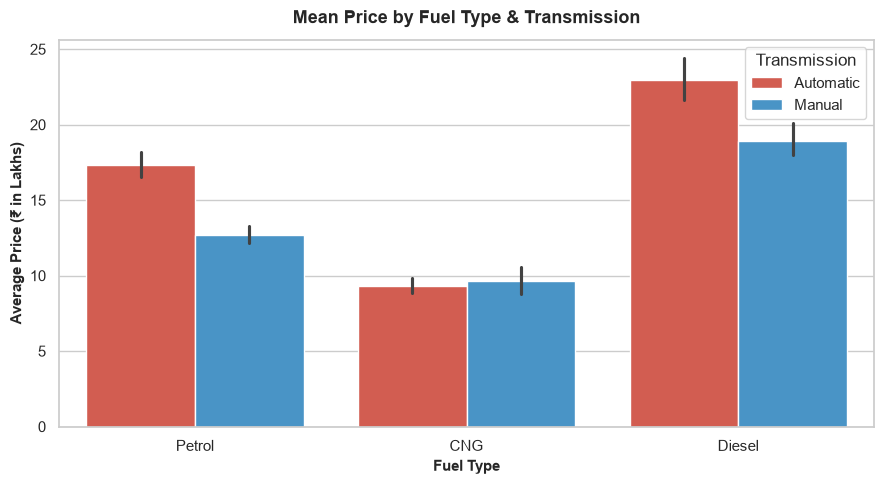

In [30]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_clean,
    x="Fuel_Type",
    y="Price_Lakh",
    hue="Transmission",
    palette={"Manual": "#3498db", "Automatic": "#e74c3c"},
)

plt.title("Mean Price by Fuel Type & Transmission", fontsize=13, weight="bold", pad=12)
plt.xlabel("Fuel Type", fontsize=11, weight="semibold")
plt.ylabel("Average Price (₹ in Lakhs)", fontsize=11, weight="semibold")
plt.legend(title="Transmission")
plt.tight_layout()
plt.show()

In [32]:
from scipy import stats
from statsmodels.stats.weightstats import ztest

print("=== STATISTICAL HYPOTHESIS TESTING ===\n")

# 1.z-test mean price of manual and automatic
manual_price = df_clean[df_clean["Transmission"] == "Manual"]["Price_Lakh"].dropna()
auto_price = df_clean[df_clean["Transmission"] == "Automatic"]["Price_Lakh"].dropna()

z_stat, z_p_value = ztest(manual_price, auto_price, value=0)
print("--- 1. Z-Test (Price: Manual vs Automatic) ---")
print(f"Z-Statistic: {z_stat:.4f} | P-Value: {z_p_value:.4e}")
if z_p_value < 0.05:
    print("Result: Reject Null. There is a significant difference in price based on transmission.\n")
else:
    print("Result: Fail to Reject Null. No significant difference in price.\n")


# 2. T-TEST Mileage between petrol and diesel cars
petrol_mileage = df_clean[df_clean["Fuel_Type"] == "Petrol"]["Mileage_Imputed"].dropna()
diesel_mileage = df_clean[df_clean["Fuel_Type"] == "Diesel"]["Mileage_Imputed"].dropna()

t_stat, t_p_value = stats.ttest_ind(petrol_mileage, diesel_mileage, equal_var=False)
print("--- 2. T-Test (Mileage: Petrol vs Diesel) ---")
print(f"T-Statistic: {t_stat:.4f} | P-Value: {t_p_value:.4e}")
if t_p_value < 0.05:
    print("Result: Reject Null. There is a significant difference in mileage between Petrol and Diesel.\n")
else:
    print("Result: Fail to Reject Null. No significant difference in mileage.\n")


# 3. CHI-SQUARE TEST (Categorical data)
# Testing if Fuel Type and Transmission Type are dependent/associated
contingency_table = pd.crosstab(df_clean['Fuel_Type'], df_clean['Transmission'])

chi2_stat, chi2_p_value, dof, expected = stats.chi2_contingency(contingency_table)
print("--- 3. Chi-Square Test (Fuel Type vs Transmission) ---")
print("Contingency Table:")
print(contingency_table)
print(f"\nChi2-Statistic: {chi2_stat:.4f} | P-Value: {chi2_p_value:.4e}")
if chi2_p_value < 0.05:
    print("Result: Reject Null. Fuel Type and Transmission choice are significantly associated (dependent).")
else:
    print("Result: Fail to Reject Null. Fuel Type and Transmission choice are independent.")

=== STATISTICAL HYPOTHESIS TESTING ===

--- 1. Z-Test (Price: Manual vs Automatic) ---
Z-Statistic: -8.9141 | P-Value: 4.9171e-19
Result: Reject Null. There is a significant difference in price based on transmission.

--- 2. T-Test (Mileage: Petrol vs Diesel) ---
T-Statistic: 8.4164 | P-Value: 9.5204e-16
Result: Reject Null. There is a significant difference in mileage between Petrol and Diesel.

--- 3. Chi-Square Test (Fuel Type vs Transmission) ---
Contingency Table:
Transmission  Automatic  Manual
Fuel_Type                      
CNG                  12      32
Diesel              100     117
Petrol              265     234

Chi2-Statistic: 12.3020 | P-Value: 2.1314e-03
Result: Reject Null. Fuel Type and Transmission choice are significantly associated (dependent).
